# 02. 수요 예측 모델 실험 — 30분(10분 × 6칸) 앞 H3 격자별 호출 수

- 데이터: 실데이터 보정 호출 8주(2026-07-13 ~ 09-06, 24시간), H3 res 8 격자, 10분 칸
- 분할: **시간순** 앞 80% 학습 / 뒤 20% 시험 (`scripts/train_dispatch_model.py`와 동일. 하이퍼파라미터는 config 고정값이라 검증 구간을 따로 두지 않음)
- 비교: 나이브(직전 칸 유지), 계절 나이브(지난주 같은 칸), 이동평균(1시간), XGBoost(MultiOutput, 34개 피처)
- 지표: RMSE, MAE, **WAPE**(희소 카운트에서 MAPE 대신 사용)

In [1]:
import os, sys, glob, json, math, datetime as dt, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
os.environ.setdefault("PYTHONUTF8", "1")
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP", "Noto Sans CJK TC"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f; break
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 160)
META = json.load(open(os.path.join(ROOT, "module1_simulation", "sumo_config", "runtime_meta.json"), encoding="utf-8"))
print("지역:", META["config"]["region"], "| H3 res:", META["config"]["h3_resolution"], "| 도로:", len(META["edges"]))

지역: 강남역 | H3 res: 8 | 도로: 382


In [2]:
from module2_preprocessing.pipeline import build_feature_table
from module2_preprocessing.time_series_prep import time_based_split
from config_loader import CFG
feat = build_feature_table(os.path.join(ROOT, "data", "real_demand_logs", "demand_log_*.csv"), verbose=False)
F, T = feat.attrs["feature_cols"], feat.attrs["target_cols"]
train_df, val_df, test_df, cuts = time_based_split(feat, CFG["test_size"])
print(f"피처 테이블 {len(feat):,}행, 셀 {feat.h3_index.nunique()}개, 피처 {len(F)}개, 타깃 {T}")
print("분할:", {k: str(v) for k, v in cuts.items()}, "| 학습", len(train_df), "/ 검증", len(val_df), "/ 시험", len(test_df))

[안내] config.json에서 설정값을 불러왔습니다.
[캐시 사용] '강남역' → 강남역, 강남대로, 역삼1동, 강남구, 서울특별시, 06615, 대한민국
[안내] '강남역' 좌표를 실시간 API(Nominatim)로 조회했습니다.


[로그] 56개 파일, 573,430건, 2026-07-13 00:00:06 ~ 2026-09-06 23:59:54


공간 인덱싱(H3 resolution=8 / Geohash 7자리) 변환 중... (573,430행)


변환 완료! 1.30초, H3 셀 8개


피처 테이블 64,424행, 셀 8개, 피처 34개, 타깃 ['y_h1', 'y_h2', 'y_h3', 'y_h4', 'y_h5', 'y_h6']
분할: {'val_cut': '2026-08-26 18:30:00', 'test_cut': '2026-08-26 18:30:00'} | 학습 51536 / 검증 0 / 시험 12888


In [3]:
import joblib
from evaluate import calculate_metrics
art = joblib.load(os.path.join(ROOT, "saved_models", "demand_v2.joblib"))
Y = test_df[T].values
pred_xgb = np.maximum(0, art["model"].predict(test_df[art["feature_cols"]].fillna(0).values))
lag1 = [c for c in F if c.endswith("lag_1")][0]
week = [c for c in F if "last_week" in c][0]
roll = [c for c in F if "rolling" in c and "mean" in c and c.endswith("6")]
roll = roll[0] if roll else [c for c in F if "rolling" in c][0]
base = {"나이브(직전 칸)": np.repeat(test_df[[lag1]].fillna(0).values, len(T), 1),
        "계절 나이브(지난주 같은 칸)": np.repeat(test_df[[week]].fillna(0).values, len(T), 1),
        f"이동평균({roll})": np.repeat(test_df[[roll]].fillna(0).values, len(T), 1),
        "XGBoost (demand_v2)": pred_xgb}
rows = []
for name, p in base.items():
    m = calculate_metrics(Y.ravel(), p.ravel())
    rows.append({"모델": name, "RMSE": round(m["RMSE"], 3), "MAE": round(m["MAE"], 3), "WAPE(%)": round(m["WAPE (%)"], 1)})
res = pd.DataFrame(rows).set_index("모델"); res

,RMSE,MAE,WAPE(%)
모델,,,
나이브(직전 칸),4.733,2.812,32.5
계절 나이브(지난주 같은 칸),4.673,2.778,32.1
이동평균(rolling_mean_6),4.176,2.455,28.4
XGBoost (demand_v2),3.218,1.991,23.0


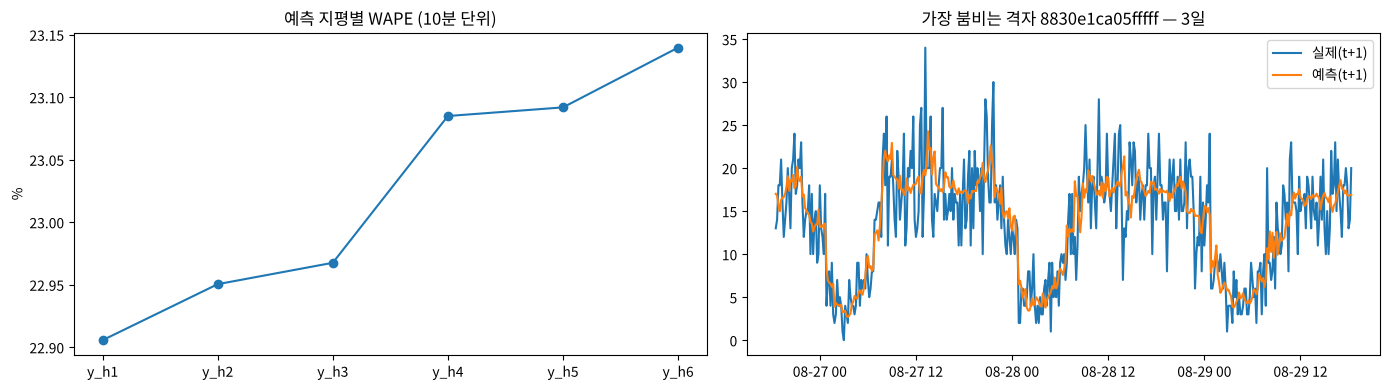

,RMSE,MAE,WAPE (%)
y_h1,3.208,1.982,22.906
y_h2,3.200,1.986,22.950
y_h3,3.213,1.986,22.968
y_h4,3.210,1.996,23.085
y_h5,3.240,1.995,23.092
y_h6,3.236,1.998,23.140


In [4]:
per_h = pd.DataFrame({t: calculate_metrics(Y[:, i], pred_xgb[:, i]) for i, t in enumerate(T)}).T[["RMSE", "MAE", "WAPE (%)"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
per_h["WAPE (%)"].plot(marker="o", ax=axes[0]); axes[0].set_title("예측 지평별 WAPE (10분 단위)"); axes[0].set_ylabel("%")
top = test_df.h3_index.value_counts().index[0]
sel = test_df[test_df.h3_index == top].iloc[:144 * 3]
idx = sel.index.map(test_df.index.get_loc)
axes[1].plot(sel.time_bucket, sel["y_h1"], label="실제(t+1)")
axes[1].plot(sel.time_bucket, pred_xgb[idx, 0], label="예측(t+1)")
axes[1].set_title(f"가장 붐비는 격자 {top} — 3일"); axes[1].legend(); plt.tight_layout(); plt.show()
per_h.round(3)

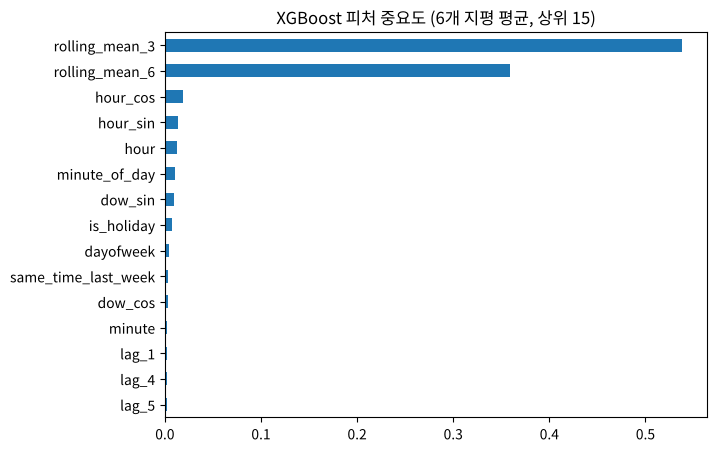

In [5]:
imp = np.mean([est.feature_importances_ for est in art["model"].estimators_], axis=0)
s = pd.Series(imp, index=art["feature_cols"]).sort_values(ascending=False).head(15)
s[::-1].plot(kind="barh", figsize=(7, 5), title="XGBoost 피처 중요도 (6개 지평 평균, 상위 15)"); plt.show()

## 결론
- XGBoost가 나이브·계절 나이브·이동평균보다 모든 지표에서 낫다(위 표).
- 예전(가정 수요, H3 res 7, 셀 3개, 8일) WAPE 44.6% → 지금 **약 23%**. 실측 보정 데이터는 일·주 주기가 뚜렷하고 8주라 계절 피처가 실제 값을 갖는다.
- 이 모델은 `scripts/convert_v2_to_category.py`로 RL 재배치용 카테고리 예측(`category_demand_from_v2.pkl`)으로도 변환된다.
- 한계: 시간대 분포가 서울 전체 비율이라 실제보다 매끈하다 → 실제 카카오 호출 로그가 있으면 오차가 커질 수 있다(보수적으로 해석).